## Imports

In [1]:
import numpy as np
from tvb.simulator.lab import *
from jr_models import habJansenRit, Olivier, jrTest, Generic2dOscillator
import pyvista as pv
import matplotlib.pyplot as plt 
from scipy.spatial import cKDTree
import mindmap as mm

## Data

In [2]:
############## Parameters ################
subject = 1
reader  = mm.io.dataset_reader(config = "../../../papers/simf/configuration.yml")
##########################################

data = reader(subject, "fwd500", "eeg", "fwd", "parc", "cras")

Coregistered EEG found
DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- eeg
- fwd
- parc
- cras
- fwd500
Missing objects:


## Connectivity

We start by designing the connectivity graph and store it in TVB's connectivity object.

#### 0. Connectivity parameters

In [3]:
# --------------------
# Graph building
# --------------------

dmax            = 1000      # Maximum distance at which to apply intra hemispheric connections
k               = 5         # Number of neighbor per region
inter_hemi_dmax = 10        # Maximum distance at which to apply inter hemispheric connections


# --------------------
# Connectivity values
# --------------------

speed = 0.6         # Axonal speed in [mm/ms]

#### 1. Create geometry graph

Number of edges:  1089.0


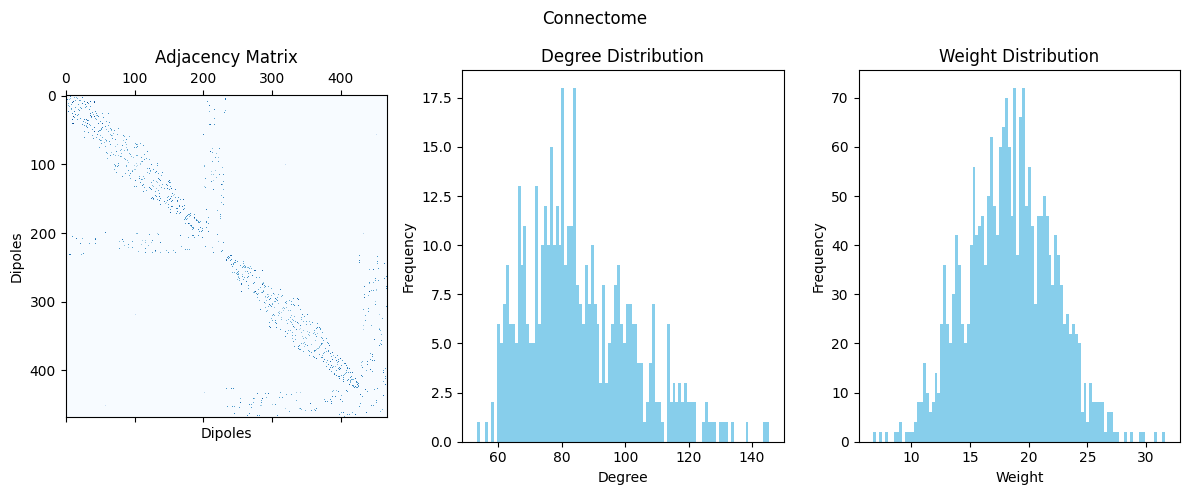

In [4]:
fwd_model = "fwd500"

geometry = mm.utils.build_geometry(data[fwd_model]["src"], dmax=100, k=5, inter_hemi_dmax=10)

print("Number of edges: ", np.sum(geometry>0)/2)
mm.viz.plot_connectome(geometry, nonzero=True)

#### 2. Store in TVB's connectivity object

In [5]:
lengths = geometry
weights = (geometry>0).astype(float)
centres = mm.utils.get_src_position(data[fwd_model]["src"]) * 1000 + data["cras"]

# labels
labels = data["parc"].label_points(centres, id=True)
#labels  = np.arange(len(centres))

# delete self loops 
weights = weights - weights*np.eye(weights.shape[0])
lenghts = lengths - lengths*np.eye(lengths.shape[0])

# instanciation Connectivity
conn = connectivity.Connectivity(
    weights       = weights,              # tract weights
    tract_lengths = lengths,              # tract lenghts
    centres       = centres,              # node position
    region_labels = labels,               # node region name
    speed         = np.array([speed]),    # axonal speed (speed at which information goes through tract)
)

# scale weights
conn.weights = conn.scaled_weights(mode="tract")

# configure
conn.configure()

# visualize graph
points = mm.utils.get_src_position(data[fwd_model]["src"])
mm.viz.plot_graph(points, geometry).show()

Widget(value='<iframe src="http://localhost:43441/index.html?ui=P_0x753b9ad82710_0&reconnect=auto" class="pyvi…

In [6]:
# Intermediate graph: try making it work with simple example (line connections)

n_nodes = 5
labels = np.arange(n_nodes)
centres = np.array([[0,0,i] for i in labels]).astype(float)

# weights
weights = np.diag(np.ones(n_nodes-1), k=1)
weights = weights + weights.T

# lengths
lengths = weights*5

conn = connectivity.Connectivity(
    weights = weights,
    tract_lengths = lengths,
    centres = centres,
    region_labels = labels,
    speed = np.array([speed]),
)

conn.weights = conn.scaled_weights(mode="region")
conn.configure()

mm.viz.plot_graph(centres, weights).show()

Widget(value='<iframe src="http://localhost:43441/index.html?ui=P_0x753b95af25d0_1&reconnect=auto" class="pyvi…

## External Input (stimulation)

The external input mimics inputs from subcortical areas or even external evoked responses. The inputs act directly on the spiny stellate neurons of layer 4 (excitatory population).

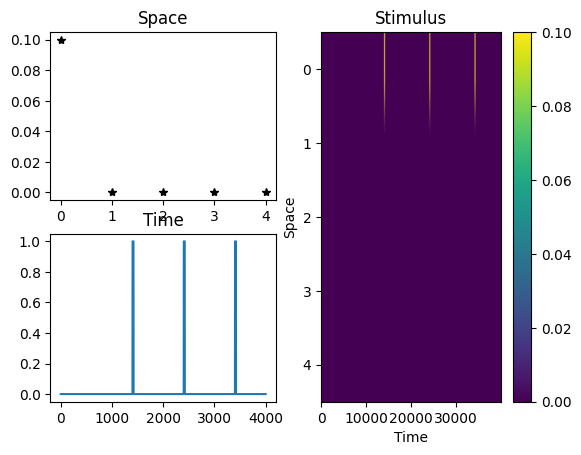

In [7]:
# weights - target specific regions
weighting      = np.zeros(conn.number_of_regions)
idx = np.argwhere(labels==200) if conn.number_of_regions > 200 else 0
weighting[idx] = 0.1          # for graph model use 200

# waveform
eqn_t = equations.PulseTrain()
eqn_t.parameters["onset"] = 1400
eqn_t.parameters["T"]     = 1000
eqn_t.parameters["tau"]   = 20

# stimulation object
stimulus = patterns.StimuliRegion(
    temporal     = eqn_t,
    connectivity = conn, 
    weight       = weighting,
)

duration = 4000
dt = 0.1 

stimulus.configure_space()
stimulus.configure_time(np.arange(0, duration, dt))

plot_pattern(stimulus)

## Simulation

Now we run the simulation using our favorite model.

In [33]:
# ------------------
# Simulation parameters
# ------------------

duration = 5000     # number of steps
dt       = 0.1      # step size

# ------------------
# Connectivity coupling
# ------------------

gc_fwd  = 40               # forward general coupling
gc_back = 0         # backward general coupling (gc_back is implemented as a ratio of bc_fwd, this is because I can only put one gc value in connectivity)


# -------------------
# Neural Mass Model
# -------------------
model = "ho"

if model == "hab":
    nmm = habJansenRit(
        mu = np.array([0.1]),
        eta = np.array([0.5]),
        tau_d = np.array([10]),
    )
    coupling_ = coupling.SigmoidalJansenRit(a=np.array([gc_fwd]))

elif model == "osc":
    nmm = models.Generic2dOscillator(
        d     = np.array([0.02]),
        #tau   = np.array([1.]),
        #f     = np.array([0.1]),
        #e     = np.array([0.]),
        #g     = np.array([-1.21]),
        #alpha = np.array([1.]),
        c     = np.array([0]),
        b     = np.array([-10]),
        #beta  = np.array([0.]),
        a     = np.array([-2]),
        I = np.array([0]),
    )
    coupling_ = coupling.Linear(a=np.array([gc_fwd]))

elif model == "jansen":
    nmm = models.JansenRit(
        p_max   = np.array([0.32]),
        p_min   = np.array([0.12]),
        mu      = np.array([0.1]),
        gc_back = np.array([gc_back]),
        b2 = np.array([1])
    )
    nmm.stvar = np.array([1], dtype=np.int32)
    coupling_ = coupling.SigmoidalJansenRit(a=np.array([gc_fwd]))

elif model == "olive":
    nmm = Olivier(
        p_max   = np.array([0.32]),
        p_min   = np.array([0.12]),
        mu      = np.array([0.1]),
        gc_back = np.array([gc_back]),
        b2 = np.array([1])
    )
    coupling_ = coupling.SigmoidalJansenRit(a=np.array([gc_fwd]))

elif model == "ho":
    nmm = Generic2dOscillator(
        d     = np.array([0.02]),
        c     = np.array([0]),
        b     = np.array([-12]),
        g     = np.array([-1.21]),
        a     = np.array([0]),
        e     = np.array([0]),
        I     = np.array([0]),
        f     = np.array([1]),
        beta  = np.array([0]),
        eta = np.array([10]),
        tau_d = np.array([0.5]),
    )
    coupling_ = coupling.Linear(a=np.array([gc_fwd]))

# -------------------
# Integrator
# -------------------
        
sigma = np.zeros(len(nmm.state_variables))
sigma = np.array([0])

integrator = integrators.HeunStochastic(dt=dt, noise=noise.Additive(nsig=sigma))


# -------------------
# Simulator
# -------------------
#initial = np.random.rand(1,len(nmm.state_variables),conn.number_of_regions,1)*0

sim = simulator.Simulator(
    connectivity      = conn,
    model             = nmm,
    coupling          = coupling_,
    integrator        = integrator,
    monitors          = [monitors.SubSample(period=1)],
    stimulus          = stimulus,
    simulation_length = duration,
    #initial_conditions = initial,
)

sim.configure()

# Run simulation
output = sim.run()


## Results

Variables:  ('V', 'C')


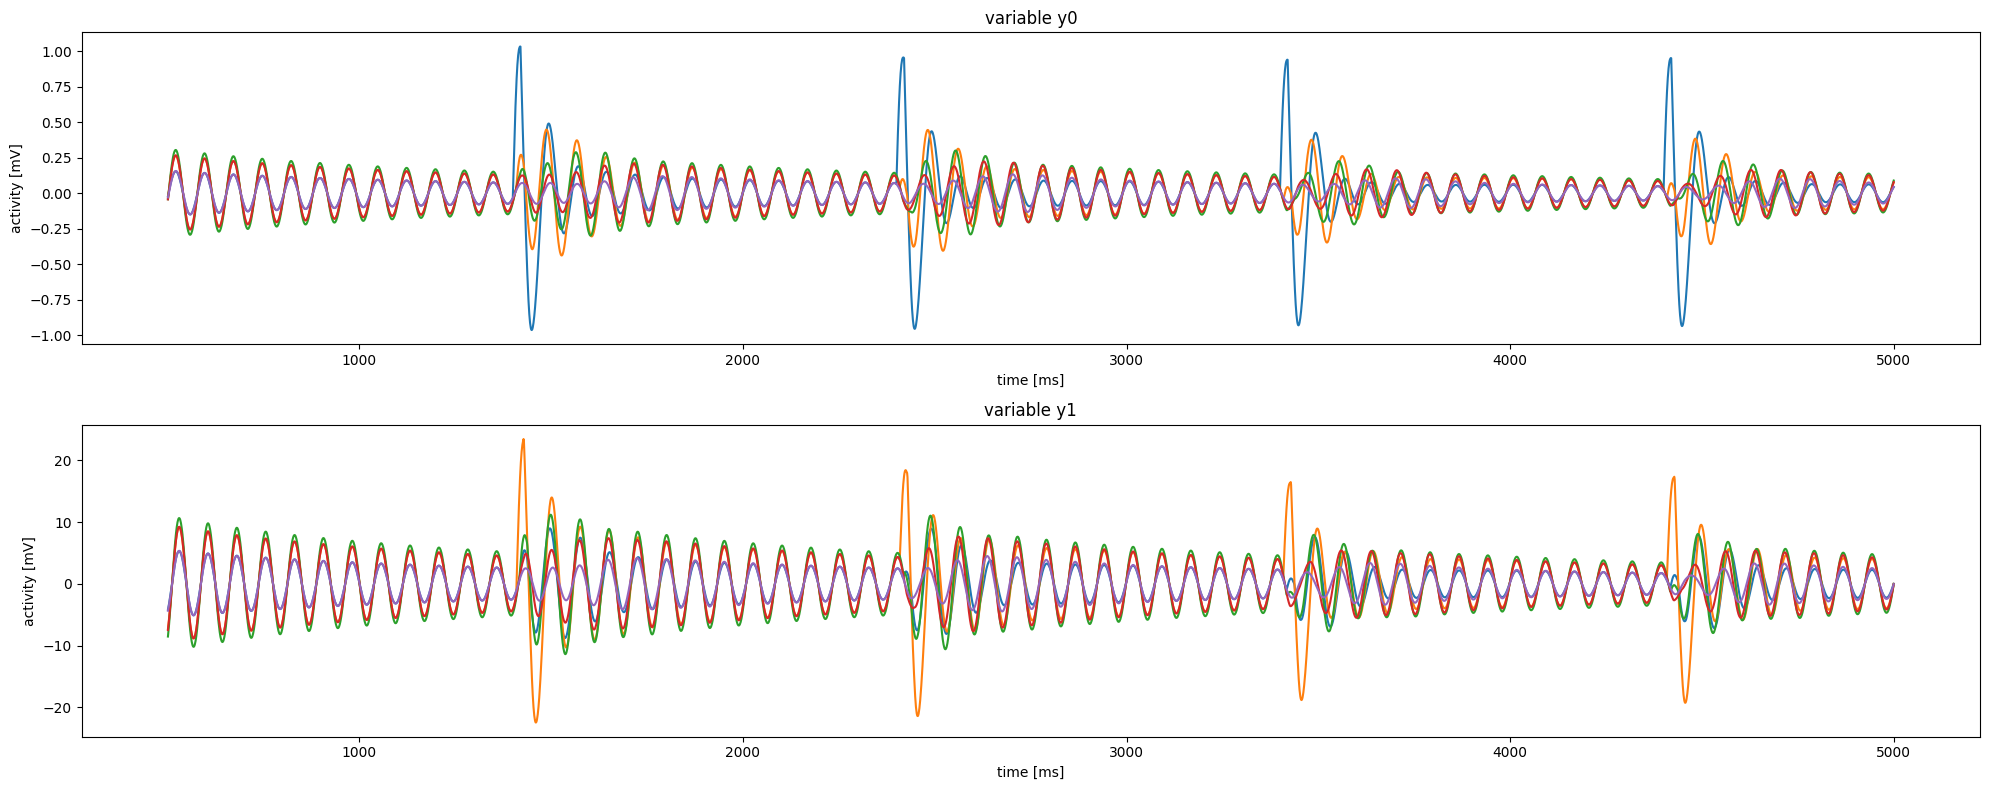

In [34]:
# ----------------
# Results
# ----------------
start = 50          # Starting point of visualizations in [ms]
end   = 10000        # Ending point of visualizations in [ms]

t       = output[0][0]
results = [output[0][1][:,i,:,0] for i in range(output[0][1].shape[1])]

#parameters = [results[:,i,:0] for i in range(len(results.shape[1]))]
if model in ["jansen", "hab", "olivier"]:
    PSP = np.subtract(results[1], results[2])
else:
    PSP = None

# ----------------
# Time series
# ----------------
print("Variables: ", nmm.variables_of_interest)

n_figs = len(results)
if PSP is not None:
    psp_fig = 1
else:
    psp_fig = 0

fig, axs = plt.subplots(nrows=n_figs+psp_fig, ncols=1, figsize=(20,4*n_figs))

# define first and last index
s_idx = int(start/dt)
e_idx = int(end/dt)

# plot
if not isinstance(axs, np.ndarray):
    axs.plot(t[s_idx:e_idx], results[0][s_idx:e_idx,:])
    axs.set_title(f"variable y{0}")
    axs.set_xlabel("time [ms]")
    axs.set_ylabel("activity [mV]") 

else:
    for i in range(n_figs):
        axs[i].plot(t[s_idx:e_idx], results[i][s_idx:e_idx,:])
        axs[i].set_title(f"variable y{i}")
        axs[i].set_xlabel("time [ms]")
        axs[i].set_ylabel("activity [mV]")

    if PSP is not None:
        axs[-1].plot(t[s_idx:e_idx], PSP[s_idx:e_idx,:])
        axs[-1].set_title("PSP")
        axs[-1].set_xlabel("time [ms]")
        axs[-1].set_ylabel("activity [mV]")

plt.tight_layout()
plt.show()

In [87]:
# --------------
# Brain time serie
# --------------

if PSP is None:
    activity = results[0][s_idx:e_idx,:].T
else:
    activity = PSP[s_idx:e_idx,:].T
activity = mm.utils.make_stc(data[fwd_model]["src"], activity, t[s_idx], 1)  # or dt maybe

activity.data = activity.data/np.mean(activity.data, axis=1)[:,None]
activity.data = np.log(np.abs(activity.data)+1)

mm.viz.plot_brain(data[fwd_model]["src"], activity).show()

Widget(value='<iframe src="http://localhost:44919/index.html?ui=P_0x73cb6e9eed90_6&reconnect=auto" class="pyvi…

    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]
Projecting source estimate to sensor space...
[done]


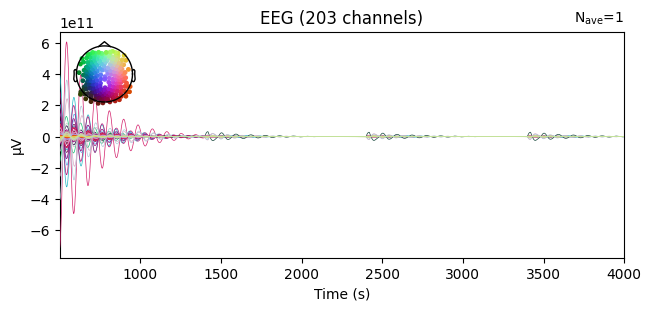

In [73]:
# ---------------
# EEG time serie
# ---------------
import mne 

activity = results[0][s_idx:e_idx,:].T
activity = mm.utils.make_stc(data[fwd_model]["src"], activity, t[s_idx], 1)  # or dt maybe

activity.data = activity.data/np.mean(activity.data, axis=1)[:,None]
activity.data = activity.data/np.abs(activity.data.max()) * 1e-8

eeg = mne.apply_forward(data[fwd_model], activity, data["eeg"].info)
eeg.data /= np.mean(eeg.data, axis=1)[:,np.newaxis]
_ = eeg.plot()

In [ ]:
mm.wcset(eeg, data["fwd"], data["cst"], )

np.float64(1.472551221697025e-12)

In [40]:
np.where(data["weight1000"][479,:]>0)

(array([453, 472, 473, 478, 499]),)